# 05 · Evaluate and calibrate the models
Use five-fold sigmoid calibration on the training split with the tuned settings, then evaluate each model on the same held-out rows. Keep the winner from Notebook 04 even if another model scores higher on the test set.

Report macro metrics and per-class precision, recall and F1. Use one-vs-rest ROC-AUC and average precision, then average across classes. For probability quality, use multiclass log loss and the mean sum of squared errors across class probabilities (multiclass Brier score). Lower is better for both losses.

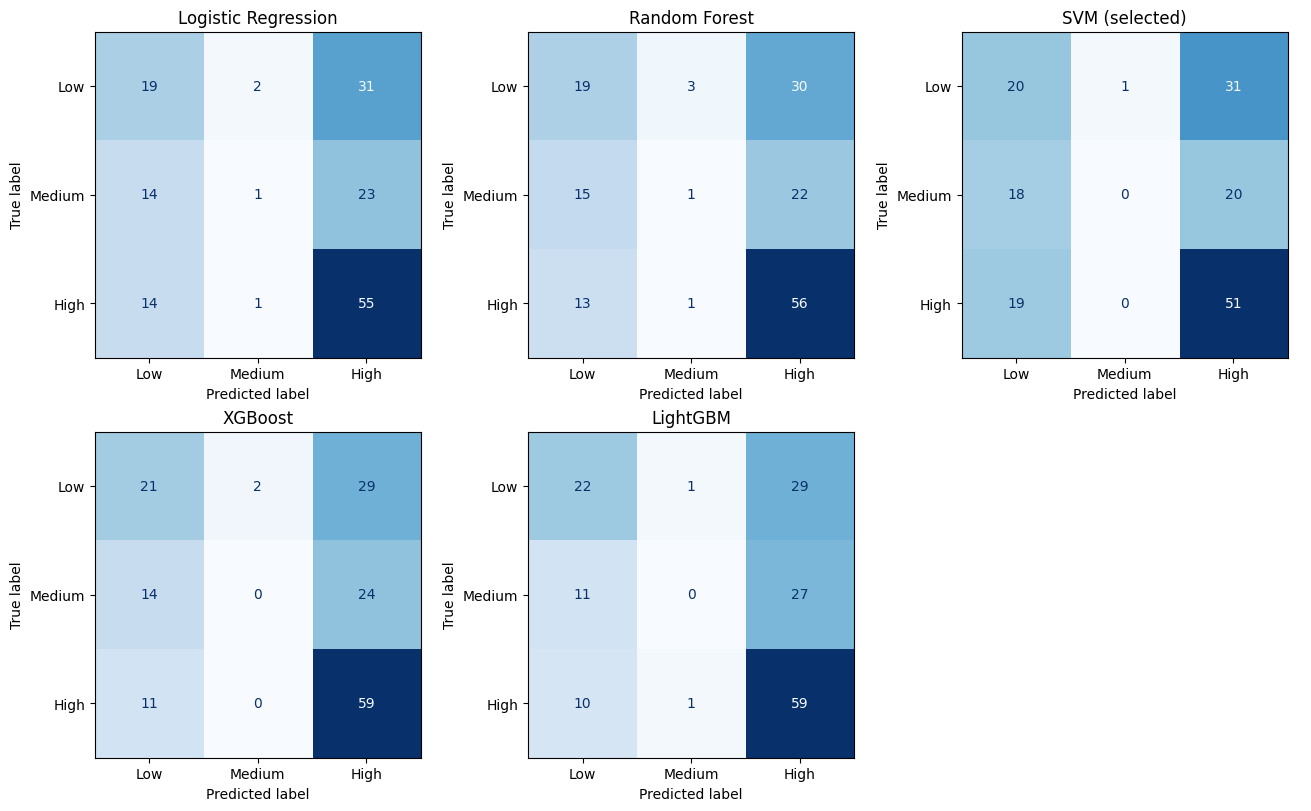

Training-majority baseline accuracy: 43.8%


,model,selected_by_cv,accuracy,precision_macro,recall_macro,f1_macro,roc_auc_macro_ovr,average_precision_macro,log_loss,brier_multiclass
0,Logistic Regression,False,0.4688,0.3863,0.3925,0.3487,0.6057,0.4757,1.0272,0.6110
1,Random Forest,False,0.4750,0.3743,0.3972,0.3532,0.6344,0.4791,1.0193,0.6073
2,SVM,True,0.4438,0.2836,0.3711,0.3200,0.6072,0.4646,1.0517,0.6299
3,XGBoost,False,0.5000,0.3278,0.4156,0.3590,0.6266,0.4707,1.0253,0.6119
4,LightGBM,False,0.5062,0.3416,0.4220,0.3670,0.6405,0.4815,1.0127,0.6023


,model,class,precision,recall,f1-score,support,roc_auc_ovr,average_precision
6,SVM,Low,0.3509,0.3846,0.367,52.0,0.6281,0.4715
7,SVM,Medium,0.0000,0.0000,0.000,38.0,0.5067,0.2464
8,SVM,High,0.5000,0.7286,0.593,70.0,0.6869,0.6760


In [2]:
from pathlib import Path
import sys

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, average_precision_score,
    classification_report, f1_score, log_loss, precision_score, recall_score,
    roc_auc_score,
)
from src.evaluate import export_model_handoff
from src.train import model_candidates
from src.preprocessing import (
    CLASS_IDS, GRAPHS, LABELS, METRICS, REPORTS, SEED, five_folds,
    make_pipeline, make_split,
)

X_train, X_test, y_train, y_test = make_split()
settings = json.loads((REPORTS / "tuned_settings.json").read_text(encoding="utf-8"))
winner = settings["winner"]
one_hot_test = np.eye(len(LABELS))[y_test.to_numpy()]
rows = []
class_rows = []
fig, axes = plt.subplots(2, 3, figsize=(13, 8), layout="constrained")
axes.flat[-1].axis("off")
folds = five_folds(X_train, y_train)

for (name, estimator), ax in zip(model_candidates().items(), axes.flat):
    pipeline = make_pipeline(estimator).set_params(**settings["models"][name])
    model = CalibratedClassifierCV(pipeline, method="sigmoid", cv=folds,
                                   ensemble=True, n_jobs=1)
    model.fit(X_train, y_train)
    assert model.classes_.tolist() == CLASS_IDS
    probs = model.predict_proba(X_test)
    predicted = model.predict(X_test)
    rows.append({
        "model": name,
        "selected_by_cv": name == winner,
        "accuracy": accuracy_score(y_test, predicted),
        "precision_macro": precision_score(y_test, predicted, average="macro", zero_division=0),
        "recall_macro": recall_score(y_test, predicted, average="macro"),
        "f1_macro": f1_score(y_test, predicted, average="macro"),
        "roc_auc_macro_ovr": roc_auc_score(y_test, probs, multi_class="ovr", average="macro"),
        "average_precision_macro": average_precision_score(one_hot_test, probs, average="macro"),
        "log_loss": log_loss(y_test, probs, labels=CLASS_IDS),
        "brier_multiclass": np.mean(np.sum((probs - one_hot_test) ** 2, axis=1)),
    })
    report = classification_report(y_test, predicted, labels=CLASS_IDS,
                                   target_names=LABELS, output_dict=True, zero_division=0)
    for i, label in enumerate(LABELS):
        class_rows.append({
            "model": name, "class": label, **report[label],
            "roc_auc_ovr": roc_auc_score(one_hot_test[:, i], probs[:, i]),
            "average_precision": average_precision_score(one_hot_test[:, i], probs[:, i]),
        })
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicted, labels=CLASS_IDS, display_labels=LABELS,
        colorbar=False, cmap="Blues", ax=ax,
    )
    ax.set_title(name + (" (selected)" if name == winner else ""))
    if name == winner:
        best_model = model
        best_probs = probs

fig.savefig(GRAPHS / "confusion_matrices.png", dpi=140)
plt.show()
results = pd.DataFrame(rows)
per_class = pd.DataFrame(class_rows)
results.to_csv(METRICS / "heldout_metrics.csv", index=False)
per_class.to_csv(METRICS / "heldout_per_class.csv", index=False)
majority = y_train.mode().iat[0]
print(f"Training-majority baseline accuracy: {y_test.eq(majority).mean():.1%}")
display(results.round(4))
display(per_class[per_class["model"] == winner].round(4))

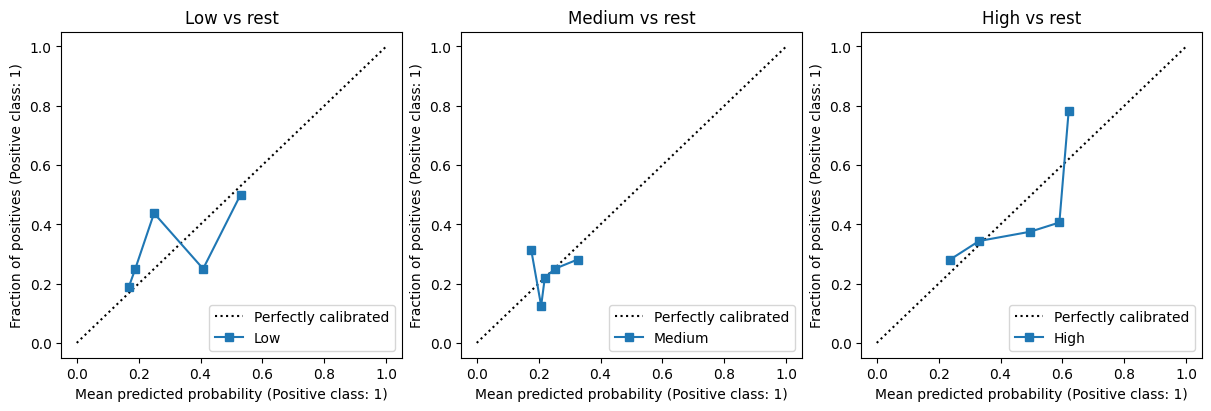

,feature,mean_f1_drop,std_f1_drop
19,Depression before pregnancy,0.0020,0.0055
14,Pregnancy plan,0.0003,0.0109
4,Marital status,0.0000,0.0000
9,History of pregnancy loss,-0.0008,0.0015
8,Disease before pregnancy,-0.0009,0.0081
2,Residence,-0.0014,0.0026
18,Mode of delivery,-0.0024,0.0024
15,Regular checkups,-0.0031,0.0023
20,Depression during pregnancy,-0.0051,0.0066
10,Family type,-0.0067,0.0042


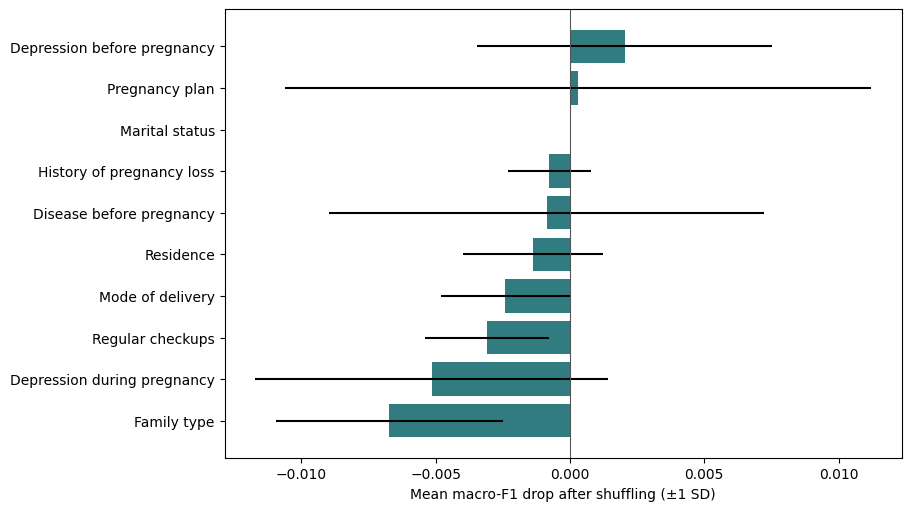

In [3]:
# Calibration curves compare the predicted probability with the observed frequency.
fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
for i, (label, ax) in enumerate(zip(LABELS, axes)):
    CalibrationDisplay.from_predictions(
        one_hot_test[:, i], best_probs[:, i], n_bins=5, strategy="quantile",
        name=label, ax=ax,
    )
    ax.set_title(f"{label} vs rest")
fig.savefig(GRAPHS / "calibration.png", dpi=140)
plt.show()

# Measure the macro-F1 change after shuffling one raw feature at a time.
importance = permutation_importance(
    best_model, X_test, y_test, scoring="f1_macro",
    n_repeats=10, random_state=SEED, n_jobs=1,
)
factors = pd.DataFrame({
    "feature": X_test.columns,
    "mean_f1_drop": importance.importances_mean,
    "std_f1_drop": importance.importances_std,
}).sort_values("mean_f1_drop", ascending=False)
factors.to_csv(METRICS / "feature_importance.csv", index=False)
display(factors.head(10).round(4))
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
top = factors.head(10).iloc[::-1]
ax.barh(top["feature"], top["mean_f1_drop"], xerr=top["std_f1_drop"], color="#317C80")
ax.axvline(0, color="#555555", linewidth=0.8)
ax.set_xlabel("Mean macro-F1 drop after shuffling (±1 SD)")
fig.savefig(GRAPHS / "feature_importance.png", dpi=140)
plt.show()

In [4]:
# Save the selected model and its train/test predictions for Member 2.
export_model_handoff(best_model, winner, X_train, X_test, y_train, y_test)
print("Saved:", winner)

Saved: SVM


Interpret the calibration curves cautiously because the test set is small. Permutation importance measures model dependence on a feature within this dataset. Correlated predictors can share importance. The ranking does not establish causation.